# What Does an Empty Battery Do to a Walking Robot?

The closed-loop walk at different servo supply voltages. Add voltages to the list to extend the sweep.

[Setup and files](README.md).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
from common import *  # noqa: F403  FMU and MuJoCo helpers, plot style

%matplotlib inline

In [2]:
VOLTAGES = [8.2, 7.4, 6.5]
runs = {v: walk_fmu(supply=v) for v in VOLTAGES}  # about a minute each

In [3]:
rows = []
for v, df in runs.items():
    i = df["batteryCurrent"].to_numpy()
    late = (df["time"] >= 2).to_numpy()
    rows.append({"supply [V]": v, "speed [m/s]": speed(df), "distance [m]": df["distance"].iloc[-1],
                 "mean current [A]": i[late].mean(), "mean power [W]": v * i[late].mean(), "peak current [A]": i.max(),
                 "stiffness [N.m/rad]": 200 * (4096 / (2 * np.pi)) / (256 * 885) * v * KT / RESISTANCE})
pd.DataFrame(rows).round(3)

,supply [V],speed [m/s],distance [m],mean current [A],mean power [W],peak current [A],stiffness [N.m/rad]
0,8.2,0.139,0.799,0.317,2.601,1.124,0.653
1,7.4,0.138,0.785,0.321,2.373,0.998,0.589
2,6.5,0.133,0.759,0.324,2.105,0.877,0.517


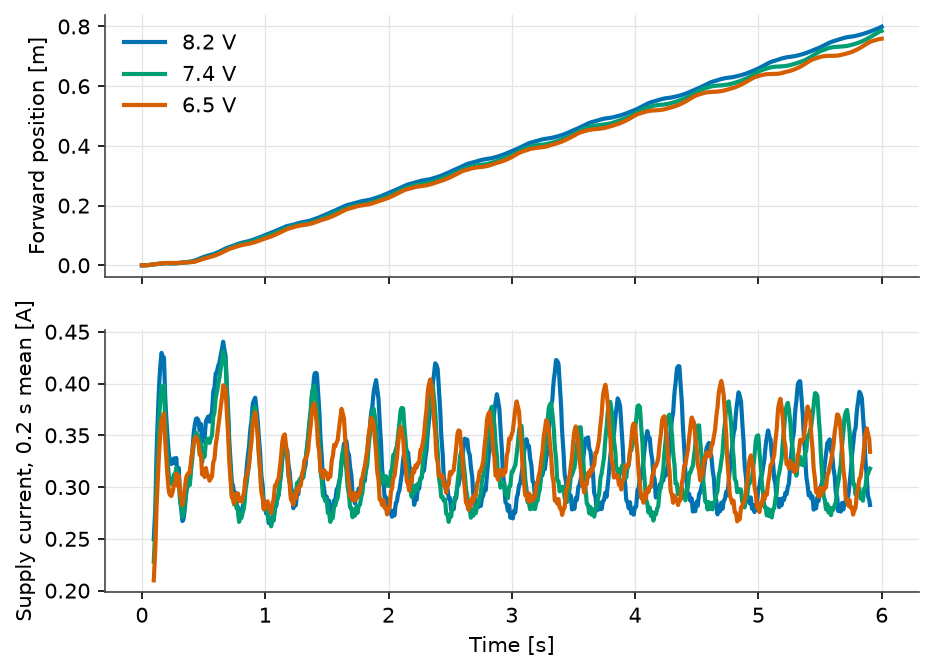

In [4]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
for (v, df), c in zip(runs.items(), [BLUE, GREEN, ORANGE, PINK]):
    a1.plot(df["time"], df["distance"], color=c, label=f"{v} V")
    a2.plot(df["time"], df["batteryCurrent"].rolling(200, center=True).mean(), color=c)
a1.set_ylabel("Forward position [m]"); a1.legend()
a2.set_ylabel("Supply current, 0.2 s mean [A]"); a2.set_xlabel("Time [s]")
plt.show()

## Pack sag

The pack resistance is an assumption. Change it and compare with the 1.7 V lost over a discharge.

In [5]:
PACK_RESISTANCE = 0.1  # ohm, cells and wiring, assumed
i = runs[7.4]["batteryCurrent"]
slope = (speed(runs[8.2]) - speed(runs[6.5])) / (8.2 - 6.5)
print(f"mean sag {1e3 * PACK_RESISTANCE * i.mean():.0f} mV, peak sag {PACK_RESISTANCE * i.max():.2f} V, "
      f"worth {slope * PACK_RESISTANCE * i.mean():.5f} m/s of walking speed")

mean sag 32 mV, peak sag 0.10 V, worth 0.00011 m/s of walking speed
